In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import json
import zipfile
from pathlib import Path
from collections import Counter
from pathlib import PurePosixPath
import re
import random
from collections import defaultdict
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

MANIFEST_PATH = Path(
    "/content/drive/MyDrive/WasteScope/manifests/video_split.json"
)

ZIP_PATH = Path(
    "/content/drive/MyDrive/WasteScope/raw_archives/segmentation_task.zip"
)

In [3]:
with zipfile.ZipFile(ZIP_PATH) as archive:
    files = [
        item.filename for item in archive.infolist()
        if not item.is_dir()
        and not item.filename.startswith("__MACOSX/")
    ]
    
    image_files = [
        name for name in files
        if Path(name).suffix.lower() in {".png", ".jpg", ".jpeg"}
    ]
    json_files = [
        name for name in files
        if Path(name).suffix.lower() == ".json"
    ]
    
    print("Image files:", len(image_files))
    print("JSON files:", json_files)
    print("\nSample image paths:")
    for name in image_files[:5]:
        print(name)

    with archive.open(json_files[0]) as file:
        annotation = json.load(file)
        
        
print("\nJSON keys:", list(annotation))
images = annotation.get("images", [])
annotations = annotation.get("annotations", [])

print("Image records:", len(images))
print("Annotation records:", len(annotations))
print("Categories:", annotation.get("categories"))

print("\nSample image records:")
for item in images[:3]:
    print(item)

Image files: 7230
JSON files: ['Segmentation Task/labels.json']

Sample image paths:
Segmentation Task/images/0019_1_1_1_0315.png
Segmentation Task/images/0020_1_1_1_0005.png
Segmentation Task/images/0055_1_1_1_0142.png
Segmentation Task/images/0054_1_1_1_0028.png
Segmentation Task/images/0107_0_1_1_0098.png

JSON keys: ['licenses', 'info', 'categories', 'images', 'annotations']
Image records: 7230
Annotation records: 36754
Categories: [{'id': 1, 'name': 'Overflow', 'supercategory': ''}, {'id': 2, 'name': 'container_yellow', 'supercategory': ''}, {'id': 3, 'name': 'container_green', 'supercategory': ''}, {'id': 4, 'name': 'container_default', 'supercategory': ''}, {'id': 5, 'name': 'container_blue', 'supercategory': ''}, {'id': 6, 'name': 'container_ash', 'supercategory': ''}, {'id': 7, 'name': 'container_oil', 'supercategory': ''}, {'id': 8, 'name': 'container_battery', 'supercategory': ''}, {'id': 9, 'name': 'container_biodegradable', 'supercategory': ''}]

Sample image records:
{'id

In [4]:
if annotations:
    item = annotations[0]
    print("First annotation summary:")
    print({
        key: item.get(key)
        for key in ["id", "image_id", "category_id", "bbox", "area", "iscrowd"]
    })
    
    segmentation = item.get("segmentation")
    print("Segmentation format:", type(segmentation).__name__)
    
    if isinstance(segmentation, list):
        print("Polygon count:", len(segmentation))
        print("Coordinate counts:", [
            len(part) if isinstance(part, list) else None
            for part in segmentation[:5]
        ])
    elif isinstance(segmentation, dict):
        print("RLE keys:", list(segmentation))

First annotation summary:
{'id': 1, 'image_id': 1, 'category_id': 1, 'bbox': [247.53, 478.5, 54.71, 42.57], 'area': 1266.0, 'iscrowd': 0}
Segmentation format: list
Polygon count: 1
Coordinate counts: [26]


In [5]:
with MANIFEST_PATH.open() as file:
    manifest = json.load(file)

video_to_split = {}
for split in ("train", "val", "test"):
    for video_id in manifest["splits"][split]:
        video_to_split[video_id] = split
        
images = annotation["images"]
annotations = annotation["annotations"]
categories = annotation["categories"]
image_ids = {image["id"] for image in images}

category_counts = Counter(item["category_id"] for item in annotations)

print("ANNOTATIONS BY CATEGORY")
for category in categories:
    print(
        f'{category["id"]:>2} | '
        f'{category["name"]:<25} | '
        f'{category_counts[category["id"]]:>6}'
    )

ANNOTATIONS BY CATEGORY
 1 | Overflow                  |   5149
 2 | container_yellow          |   5191
 3 | container_green           |   4909
 4 | container_default         |  12349
 5 | container_blue            |   5448
 6 | container_ash             |    212
 7 | container_oil             |    983
 8 | container_battery         |   1301
 9 | container_biodegradable   |   1212


In [6]:
overflow_categories = [
    category for category in categories
    if category["name"].strip().lower() == "overflow"
]

overflow_id = overflow_categories[0]["id"]
overflow_annotations = [
    item for item in annotations
    if item["category_id"] == overflow_id
]

overflow_per_image = Counter(
    item["image_id"] for item in overflow_annotations
)

print("Overflow instances:", len(overflow_annotations))
print("Positive images:", len(overflow_per_image))
print("Negative images:", len(images) - len(overflow_per_image))
print(
    "Overflow annotations without segmentation:",
    sum(not item.get("segmentation") for item in overflow_annotations)
)

Overflow instances: 5149
Positive images: 4197
Negative images: 3033
Overflow annotations without segmentation: 0


In [7]:
split_images = {"train": [], "val": [], "test": []}
unmapped_videos = set()
invalid_filenames = []

for image in images:
    filename = PurePosixPath(image["file_name"]).name
    match = re.match(r"^(\d{4})_", filename)

    if match is None:
        invalid_filenames.append(filename)
        continue

    video_id = match.group(1)
    split = video_to_split.get(video_id)

    if split is None:
        unmapped_videos.add(video_id)
        continue

    split_images[split].append(image)

print("Invalid filenames:", invalid_filenames[:10])
print("Videos missing from manifest:", sorted(unmapped_videos))

Invalid filenames: []
Videos missing from manifest: []


In [8]:
print("SPLIT SUMMARY")
for split, records in split_images.items():
    positives = sum(overflow_per_image[image["id"]] > 0 for image in records)
    instances = sum(overflow_per_image[image["id"]] for image in records)
    
    videos = {
        PurePosixPath(image["file_name"]).name.split("_")[0]
        for image in records
    }

    print(
        f"{split:5} | videos={len(videos):3} "
        f"| images={len(records):4} "
        f"| positive={positives:4} "
        f"| negative={len(records) - positives:4} "
        f"| overflow_instances={instances:4}"
    )

SPLIT SUMMARY
train | videos= 27 | images=5090 | positive=2764 | negative=2326 | overflow_instances=3442
val   | videos=  5 | images=1030 | positive= 629 | negative= 401 | overflow_instances= 861
test  | videos=  6 | images=1110 | positive= 804 | negative= 306 | overflow_instances= 846


In [9]:
polygon_counts = Counter()
invalid_masks = []

for item in overflow_annotations:
    segments = item.get("segmentation")

    valid = (
        isinstance(segments, list) and bool(segments)
        and all(
            isinstance(polygon, list)
            and len(polygon) >= 6 and len(polygon) % 2 == 0
            for polygon in segments
        )
    )

    if valid:
        polygon_counts[len(segments)] += 1
    else:
        invalid_masks.append(item["id"])

print("Polygons per instance:", dict(sorted(polygon_counts.items())))
print("Invalid mask structures:", len(invalid_masks))
print("Example invalid IDs:", invalid_masks[:5])

Polygons per instance: {1: 5149}
Invalid mask structures: 0
Example invalid IDs: []


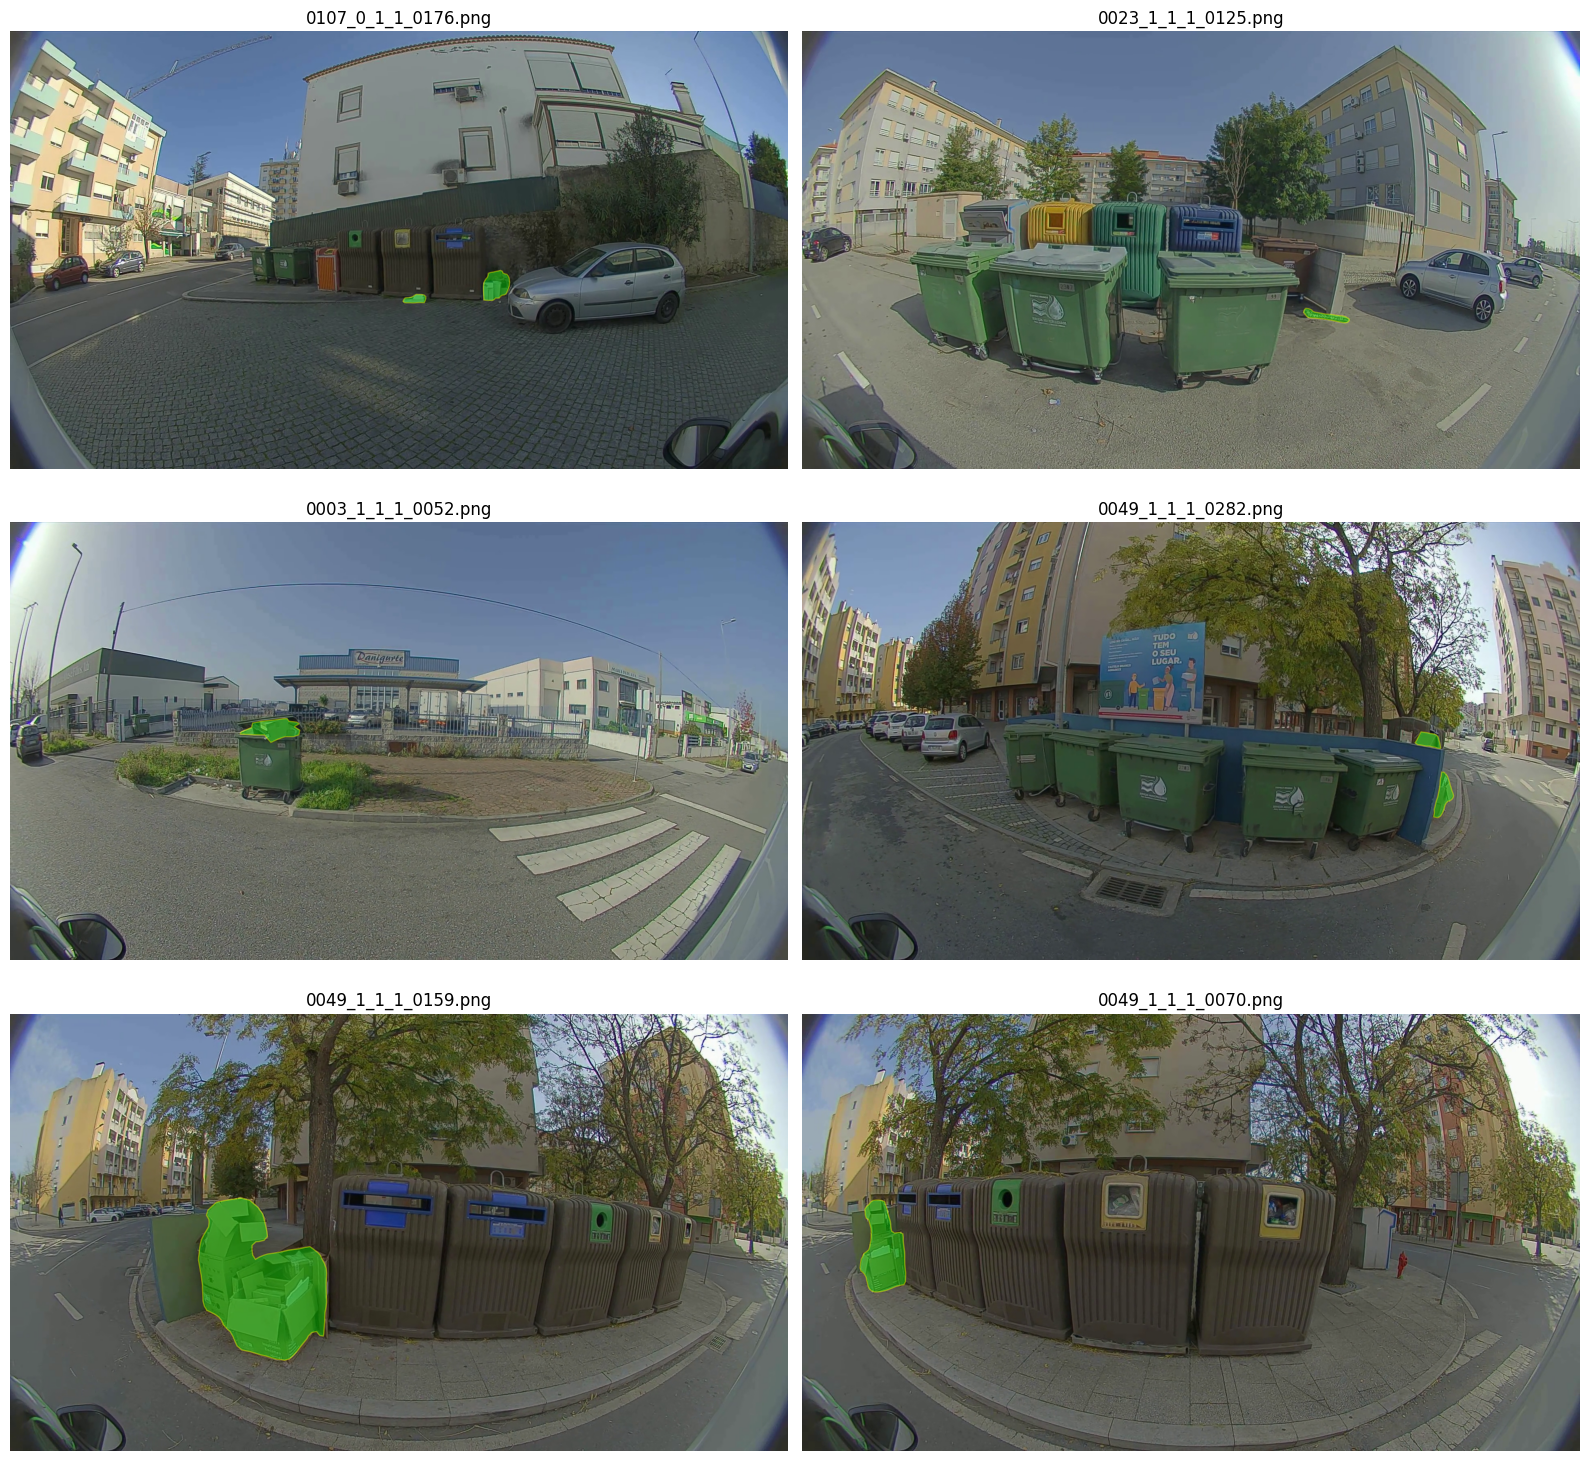

In [10]:
annotations_by_image = defaultdict(list)
for item in overflow_annotations:
    annotations_by_image[item["image_id"]].append(item)
    
positive_train = [
    image for image in split_images["train"]
    if annotations_by_image[image["id"]]
]

samples = random.Random(42).sample(positive_train, 6)
image_members = {
    PurePosixPath(name).name: name for name in image_files
}

fig, axes = plt.subplots(3, 2, figsize=(16, 15))
with zipfile.ZipFile(ZIP_PATH) as archive:
    for ax, image in zip(axes.flat, samples):
        filename = PurePosixPath(image["file_name"]).name

        with archive.open(image_members[filename]) as file:
            ax.imshow(Image.open(file).convert("RGB"))

        for item in annotations_by_image[image["id"]]:
            polygon = item["segmentation"][0]
            points = list(zip(polygon[0::2], polygon[1::2]))
            ax.add_patch(Polygon(
                points, facecolor="lime",
                edgecolor="yellow", alpha=0.4
            ))

        ax.set_title(filename)
        ax.axis("off")

fig.tight_layout()
plt.show()